# Feature Selection

This notebook takes the feature table produced by the preprocessing step and reduces it to a
compact, non-redundant subset. With only 15 subjects and a leave-one-subject-out (LOSO)
evaluation, the selection cannot be performed once on the whole dataset: anything that learns
from the data — imputation, scaling, redundancy filtering, ranking — must be fitted inside each
training fold. The deliverable is therefore not a fixed reduced table but a selection *procedure*
embedded in a scikit-learn pipeline.

Two selection strategies are compared. The first is a two-step filter: a correlation filter
removes redundant features, then `SelectKBest` keeps those with the highest mutual information
with the class. The second is **mRMR** (minimum redundancy, maximum relevance), which combines
the two criteria in a single greedy step. Both are evaluated with LOSO on the three-class and
the binary task.

Three cleaning/selection steps precede the classifier, and all three now run entirely inside each
LOSO fold. Features missing in more than 30% of a fold's training windows are dropped by
`MissingnessFilter`, since imputing a mostly-absent column would fabricate data rather than
recover it — recomputing this threshold per fold, instead of once on the whole dataset, means the
held-out subject's own missingness never influences which columns are even considered usable. The
remaining missing values are then filled with the column median, likewise computed inside each
fold, so the held-out subject never influences the imputation either.


## Imports

In [ ]:
import os
from functools import partial

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import LeaveOneGroupOut, cross_val_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.pipeline import Pipeline
from sklearn.base import BaseEstimator, TransformerMixin    # base classes for the custom selectors defined below
from sklearn.neighbors import KNeighborsClassifier          # probe classifier used to compare the two selectors

## Loading and cleaning

The feature table is loaded and, as a safeguard, any fully-empty row is removed and the label
and subject columns are cast back to integers. All remaining columns are kept as
`all_feature_cols` — this full-width table is what actually enters the LOSO pipelines below.

The cell also prints a whole-dataset missingness snapshot (`explore_cols`), purely to illustrate
the >30% threshold for the exploratory plots that follow. It is not used by the real pipelines,
which instead recompute this threshold per fold via `MissingnessFilter` (defined further down),
so the held-out subject never influences which columns are considered usable.


In [ ]:
OUT_DIR = "chest_outputs"
features = pd.read_csv(os.path.join(OUT_DIR, "features.csv"))
features = features.dropna(subset=["subject_id", "label"]).reset_index(drop=True)
features["subject_id"] = features["subject_id"].astype(int)
features["label"] = features["label"].astype(int)

META = ["label", "label_name", "subject_id"]
all_feature_cols = [c for c in features.columns if c not in META]

# Whole-dataset missingness snapshot, for the exploratory plots ONLY (below). The real LOSO
# pipelines do NOT use this: the 30%-missingness threshold is recomputed inside every training
# fold by MissingnessFilter (defined further down), so the held-out subject never influences
# which columns are considered too sparse to use
NA_THRESHOLD = 0.30
na_fraction_all = features[all_feature_cols].isna().mean()
dropped_all = na_fraction_all[na_fraction_all > NA_THRESHOLD].index.tolist()
explore_cols = [c for c in all_feature_cols if c not in dropped_all]

print(f"{features.shape[0]} windows, {len(all_feature_cols)} features before cleaning")
print(f"Whole-dataset snapshot (exploratory only): {len(explore_cols)} features would survive "
      f"the >{int(NA_THRESHOLD*100)}% missingness threshold")
print(f"Dropped in this snapshot: {dropped_all or 'none'}")
print("\nNote: the actual LOSO pipelines below recompute this threshold per fold via "
      "MissingnessFilter, so the exact set of kept columns can vary slightly fold to fold.")

X = features[all_feature_cols].values        # full width; MissingnessFilter narrows this per fold
y = features["label"].values                  # 1 = baseline, 2 = stress, 3 = amusement
groups = features["subject_id"].values

6123 windows, 80 features before cleaning
Whole-dataset snapshot (exploratory only): 78 features would survive the >30% missingness threshold
Dropped in this snapshot: ['SCR_ipi_mean', 'SCR_ipi_mean_rel']

Note: the actual LOSO pipelines below recompute this threshold per fold via MissingnessFilter, so the exact set of kept columns can vary slightly fold to fold.


## Exploratory analysis

The plots below are computed on the whole dataset and serve only to understand the data; they
are not the selection that enters the results, which is fitted inside the folds further down.
Missing values are median-filled here purely for plotting.


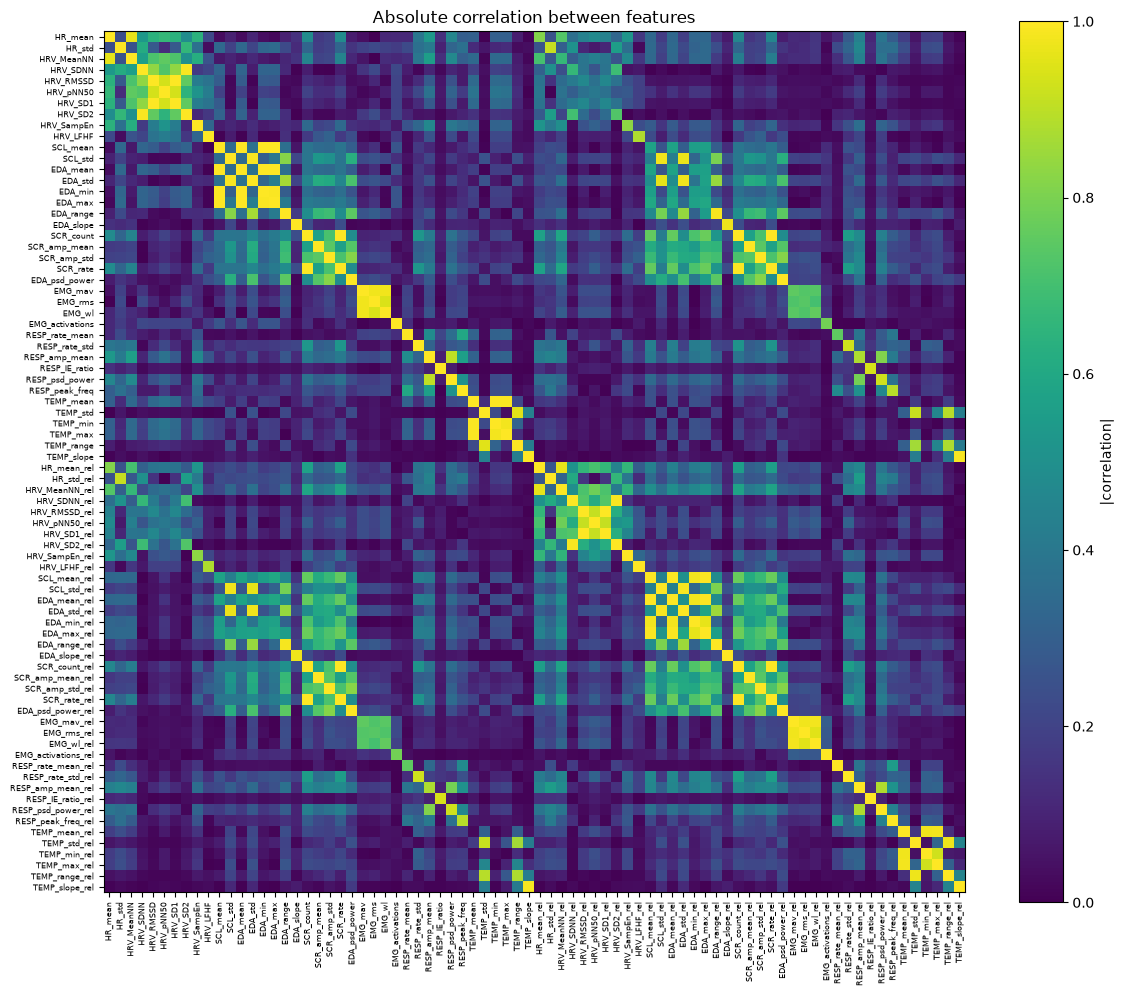

60 feature pairs with |correlation| > 0.9 (redundancy candidates)
  HR_mean            ~ HRV_MeanNN          r = -0.96
  HR_std             ~ HR_std_rel          r = +0.91
  HRV_SDNN           ~ HRV_SD2             r = +0.99
  HRV_RMSSD          ~ HRV_pNN50           r = +0.94
  HRV_RMSSD          ~ HRV_SD1             r = +1.00
  HRV_pNN50          ~ HRV_SD1             r = +0.94
  SCL_mean           ~ EDA_mean            r = +1.00
  SCL_mean           ~ EDA_min             r = +1.00
  SCL_mean           ~ EDA_max             r = +1.00
  SCL_std            ~ EDA_std             r = +0.99
  SCL_std            ~ SCL_std_rel         r = +0.98
  SCL_std            ~ EDA_std_rel         r = +0.97
  EDA_mean           ~ EDA_min             r = +1.00
  EDA_mean           ~ EDA_max             r = +1.00
  EDA_std            ~ SCL_std_rel         r = +0.96


In [ ]:
X_explore = features[explore_cols].fillna(features[explore_cols].median()).values

corr = np.corrcoef(X_explore, rowvar=False)

fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(np.abs(corr), cmap="viridis", vmin=0, vmax=1)
ax.set_xticks(range(len(explore_cols))); ax.set_xticklabels(explore_cols, rotation=90, fontsize=6)
ax.set_yticks(range(len(explore_cols))); ax.set_yticklabels(explore_cols, fontsize=6)
fig.colorbar(im, label="|correlation|")
ax.set_title("Absolute correlation between features")
plt.tight_layout(); plt.show()

# Same 0.9 threshold used by CorrelationFilter inside the LOSO folds below
pairs = [(explore_cols[i], explore_cols[j], corr[i, j])
         for i in range(len(explore_cols)) for j in range(i + 1, len(explore_cols))
         if abs(corr[i, j]) > 0.9]
print(f"{len(pairs)} feature pairs with |correlation| > 0.9 (redundancy candidates)")
for a, b, r in pairs[:15]:
    print(f"  {a:18s} ~ {b:18s}  r = {r:+.2f}")

Where the correlation heatmap above flags **redundant** features, the ranking below estimates
**relevance**: which features carry the most information about the class on their own, using the
same mutual-information criterion later used by `SelectKBest` inside the LOSO folds. As with the
correlation analysis, this is a whole-dataset preview, not the actual per-fold ranking.

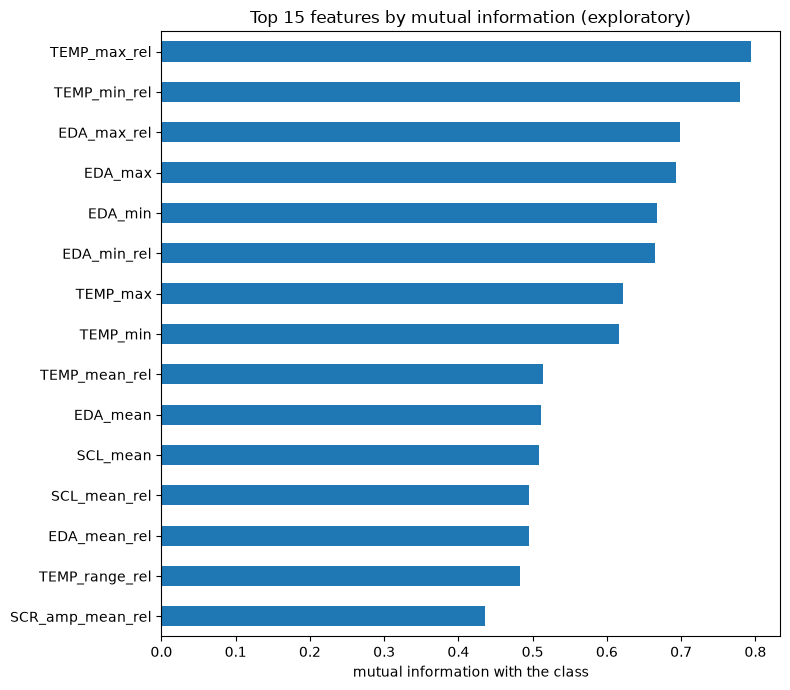

Top 15 features by mutual information:
TEMP_max_rel     0.793478
TEMP_min_rel     0.778728
EDA_max_rel      0.698530
EDA_max          0.692898
EDA_min          0.667935
EDA_min_rel      0.665450
TEMP_max         0.621604
TEMP_min         0.616558
TEMP_mean_rel    0.513277
EDA_mean         0.511494
dtype: float64


In [ ]:
# mutual_info_classif estimates MI between each (continuous) feature and the (discrete) class
# with a k-nearest-neighbour estimator (Ross 2014), so the features need no discretisation
mi = mutual_info_classif(StandardScaler().fit_transform(X_explore), y, random_state=0)
ranking = pd.Series(mi, indexexplore_cols).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 7))
ranking.head(15).iloc[::-1].plot(kind="barh", ax=ax)
ax.set_title("Top 15 features by mutual information (exploratory)")
ax.set_xlabel("mutual information with the class")
plt.tight_layout(); plt.show()

print("Top 15 features by mutual information:")
print(ranking.head(10))

Two things at a glance: how imbalanced the three classes are, and how four representative
features (one each from EDA, temperature, heart rate and respiration) separate across them.
Distributions overlap substantially — consistent with no single feature fully separating the
classes — which is why the classifiers rely on many features together, not one.

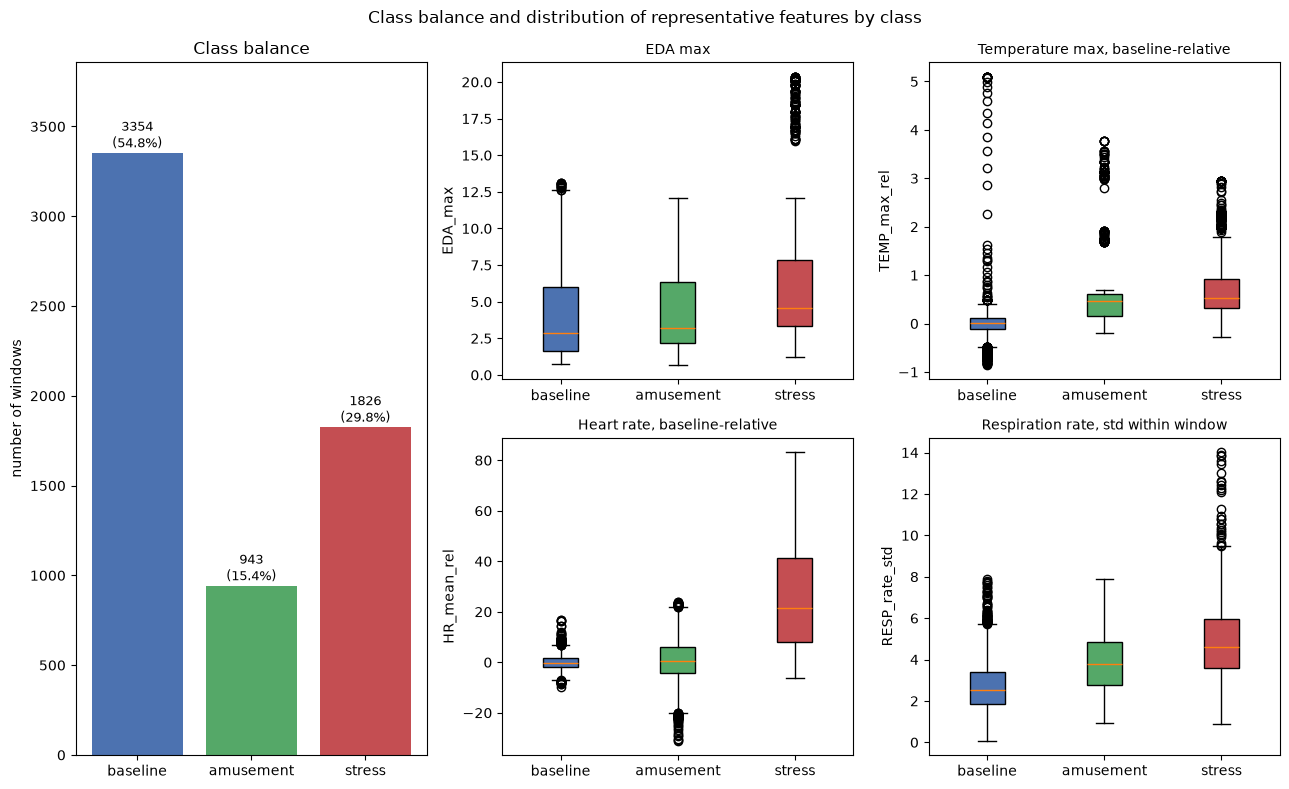

In [ ]:
CLASS_ORDER = ["baseline", "amusement", "stress"]
CLASS_COLORS = {"baseline": "#4C72B0", "amusement": "#55A868", "stress": "#C44E52"}
DIST_FEATURES = ["EDA_max", "TEMP_max_rel", "HR_mean_rel", "RESP_rate_std"]
DIST_TITLES = {
    "EDA_max": "EDA max",
    "TEMP_max_rel": "Temperature max, baseline-relative",
    "HR_mean_rel": "Heart rate, baseline-relative",
    "RESP_rate_std": "Respiration rate, std within window",
}

fig = plt.figure(figsize=(13, 8))
gs = fig.add_gridspec(2, 3, width_ratios=[1, 1, 1])

# Left panel (spans both rows): class balance
ax_bal = fig.add_subplot(gs[:, 0])
class_counts = features["label_name"].value_counts().reindex(CLASS_ORDER)
ax_bal.bar(class_counts.index, class_counts.values,
           color=[CLASS_COLORS[c] for c in class_counts.index])
for i, v in enumerate(class_counts.values):
    ax_bal.text(i, v + 30, f"{v}\n({v / class_counts.sum() * 100:.1f}%)", ha="center", fontsize=9)
ax_bal.set_title("Class balance")
ax_bal.set_ylabel("number of windows")
ax_bal.margins(y=0.15)

# Right 2x2 grid: distributions by class
grid_positions = [(0, 1), (0, 2), (1, 1), (1, 2)]
for (row, col), feat in zip(grid_positions, DIST_FEATURES):
    ax = fig.add_subplot(gs[row, col])
    data = [features.loc[features["label_name"] == cls, feat].dropna() for cls in CLASS_ORDER]
    bp = ax.boxplot(data, tick_labels=CLASS_ORDER, patch_artist=True)
    for patch, cls in zip(bp["boxes"], CLASS_ORDER):
        patch.set_facecolor(CLASS_COLORS[cls])
    ax.set_title(DIST_TITLES[feat], fontsize=10)
    ax.set_ylabel(feat)

fig.suptitle("Class balance and distribution of representative features by class")
plt.tight_layout()
plt.show()



## Selection methods

Three transformers are defined so they can be fitted inside the pipeline, on the training data of
each fold only.

`MissingnessFilter` is fitted first, ahead of either selector: it recomputes the >30%-missingness
threshold from scratch on the training fold's data only and drops columns accordingly, so the
held-out subject's data never influences which columns are even considered usable.

The **correlation filter** drops features strongly correlated with one already kept; candidates
are visited in decreasing order of mutual information with the class (computed on the training
fold only), so of two correlated features the more informative one is always kept, not simply
whichever happened to come first in column order. The **mRMR selector** grows the feature set
greedily, at each step adding the feature with the best relevance-minus-redundancy score:
relevance is the mutual information with the class, redundancy is the mean absolute correlation
with the features already selected.

In [ ]:
class MissingnessFilter(BaseEstimator, TransformerMixin):
    """Drop columns missing in more than `threshold` of the fold's training rows. Fitted on the
    training fold only, so the missingness threshold never sees the held-out subject."""
    def __init__(self, threshold=0.30):
        self.threshold = threshold

    def fit(self, X, y=None):
        X = np.asarray(X, float)
        na_fraction = np.isnan(X).mean(axis=0)
        self.keep_ = np.where(na_fraction <= self.threshold)[0].tolist()
        return self

    def transform(self, X):
        return np.asarray(X, float)[:, self.keep_]


class CorrelationFilter(BaseEstimator, TransformerMixin):
    """Drop features whose absolute correlation with an already-kept feature exceeds `threshold`.
    Candidates are visited in decreasing order of mutual information with the class, so of two
    correlated features the more informative one is always kept rather than whichever happens to
    come first in column order."""
    def __init__(self, threshold=0.9):
        self.threshold = threshold

    def fit(self, X, y):
        X = np.asarray(X, float)
        c = np.nan_to_num(np.abs(np.corrcoef(X, rowvar=False)))
        n = c.shape[0]
        relevance = mutual_info_classif(X, y, random_state=0)
        order = np.argsort(relevance)[::-1]   # column indices, most informative first
        drop = set()
        for pos, i in enumerate(order):
            if i in drop:                      # already eliminated by a more informative feature
                continue
            for j in order[pos + 1:]:           # only compare against less informative candidates
                if j not in drop and c[i, j] > self.threshold:
                    drop.add(int(j))
        self.keep_ = [i for i in range(n) if i not in drop]
        return self

    def transform(self, X):
        return np.asarray(X, float)[:, self.keep_]


class MRMRSelector(BaseEstimator, TransformerMixin):
    """Greedy mRMR selection: maximise MI(feature, class) minus mean |correlation| with the
    already-selected features. Redundancy is measured by Pearson correlation."""
    def __init__(self, k=15):
        self.k = k

    def fit(self, X, y):
        X = np.asarray(X, float)
        n = X.shape[1]
        k = min(self.k, n)
        relevance = mutual_info_classif(X, y, random_state=0)
        redundancy = np.nan_to_num(np.abs(np.corrcoef(X, rowvar=False)))
        selected = [int(np.argmax(relevance))]                  # start from the single most relevant feature
        candidates = [i for i in range(n) if i != selected[0]]
        while len(selected) < k:
            scores = [relevance[f] - redundancy[f, selected].mean() for f in candidates]
            best = candidates[int(np.argmax(scores))]
            selected.append(best)
            candidates.remove(best)
        self.selected_ = selected
        return self

    def transform(self, X):
        return np.asarray(X, float)[:, self.selected_]

## Comparison in LOSO

Both pipelines start with the same missingness filter and imputation/scaling, and share the same
probe classifier (k-nearest neighbours); the only difference is the redundancy/selection step.
Everything — including which columns even survive the missingness threshold — is fitted inside
the folds via `cross_val_score`, so the held-out subject never influences any part of the
procedure. The k-NN is a probe to compare the two selectors end to end — the actual model
comparison belongs to the modelling stage.


In [6]:
K_BEST = 15
mi_score = partial(mutual_info_classif, random_state=0)
logo = LeaveOneGroupOut()
y_binary = (y == 2).astype(int)              # stress vs. non-stress

pipeline_filter = Pipeline([
    ("missingness", MissingnessFilter(threshold=NA_THRESHOLD)),
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
    ("redundancy", CorrelationFilter(threshold=0.9)),
    ("select", SelectKBest(mi_score, k=K_BEST)),
    ("clf", KNeighborsClassifier(n_neighbors=5)),
])

pipeline_mrmr = Pipeline([
    ("missingness", MissingnessFilter(threshold=NA_THRESHOLD)),
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
    ("select", MRMRSelector(k=K_BEST)),
    ("clf", KNeighborsClassifier(n_neighbors=5)),
])

def loso_f1(pipe, target):
    return cross_val_score(pipe, X, target, groups=groups, cv=logo, scoring="f1_macro")

rows = []
for name, pipe in [("correlation + SelectKBest", pipeline_filter), ("mRMR", pipeline_mrmr)]:
    three, binary = loso_f1(pipe, y), loso_f1(pipe, y_binary)
    rows.append({"method": name,
                 "three-class F1-macro": f"{three.mean():.3f} +/- {three.std():.3f}",
                 "binary F1-macro": f"{binary.mean():.3f} +/- {binary.std():.3f}"})

comparison = pd.DataFrame(rows).set_index("method")
print(comparison.to_string())

                          three-class F1-macro  binary F1-macro
method                                                         
correlation + SelectKBest      0.686 +/- 0.183  0.805 +/- 0.212
mRMR                           0.642 +/- 0.119  0.788 +/- 0.220


## Statistical comparison of the two selectors


The two selection procedures reach similar mean F1-macro, but the per-subject variance is large.
To check whether the small difference is meaningful, a Wilcoxon signed-rank test is applied to the
two vectors of 15 per-subject scores, paired by subject. A high p-value means the two selectors are
statistically indistinguishable. The same paired test is used later to compare the classification
models.


In [8]:
from scipy.stats import wilcoxon

# Per-subject F1-macro for both selectors (paired by subject, same LOSO splits)
per_subject = {
    "filter": {"three-class": loso_f1(pipeline_filter, y),
               "binary":      loso_f1(pipeline_filter, y_binary)},
    "mRMR":   {"three-class": loso_f1(pipeline_mrmr, y),
               "binary":      loso_f1(pipeline_mrmr, y_binary)},
}

for task in ["three-class", "binary"]:
    a = per_subject["filter"][task]
    b = per_subject["mRMR"][task]
    stat, p = wilcoxon(a, b)
    verdict = "no significant difference" if p > 0.05 else "significant difference"
    print(f"{task}: filter {a.mean():.3f} vs mRMR {b.mean():.3f} "
          f"| Wilcoxon p = {p:.3f} -> {verdict}")

three-class: filter 0.686 vs mRMR 0.642 | Wilcoxon p = 0.121 -> no significant difference
binary: filter 0.805 vs mRMR 0.788 | Wilcoxon p = 0.421 -> no significant difference


## Notes

Both selectors are fitted entirely inside the LOSO folds, so nothing from the held-out subject
influences which features are kept. The two-step filter (correlation + `SelectKBest`) and mRMR
pursue the same goal — relevance with low redundancy — the first in two explicit steps, the
second jointly; comparing them shows whether the joint criterion changes the outcome.

The F1-macro figures above are a sanity check with k-NN, not final results. The winning selection
procedure feeds the modelling stage, where it is refitted inside each fold of the actual
classification pipeline and the k-NN step is replaced by the classifiers under comparison.